# 02 · Laboratorio de rendimiento: índices, planes y Query Store

Cada variante se ejecutó 5 veces en caliente y 5 en frío (con `DBCC DROPCLEANBUFFERS` antes de cada corrida). Las tablas muestran la **mediana**. Todas las variantes de un experimento devuelven el mismo número de filas y el mismo checksum.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLAS = RAIZ / "reports" / "tablas"

def leer(nombre: str) -> pd.DataFrame:
    return pd.read_csv(TABLAS / f"{nombre}.csv")

def miles(x) -> str:
    return f"{x:,.0f}".replace(",", ".")

def dec(x, n=1) -> str:
    return f"{x:,.{n}f}".replace(",", "X").replace(".", ",").replace("X", ".")


In [2]:
exp = leer('experimentos_tuning')
cols = ['codigo_experimento', 'rol_comparacion', 'operador_principal', 'lecturas_logicas',
        'duracion_ms_caliente', 'duracion_ms_frio', 'speedup_caliente_x', 'speedup_frio_x', 'filas_devueltas']
exp[cols]

,codigo_experimento,rol_comparacion,operador_principal,lecturas_logicas,duracion_ms_caliente,duracion_ms_frio,speedup_caliente_x,speedup_frio_x,filas_devueltas
0,E1_A_HEAP,ANTES,Table Scan (heap),78325,754.689,938.690,1.00,1.00,11022
1,E1_B_KEYLOOKUP,INTERMEDIO,Index Seek + Key Lookup,35174,24.029,452.899,31.41,2.07,11022
2,E1_C_COVERING,DESPUES,Index Seek,65,2.172,3.159,347.46,297.15,11022
3,E2_A_HEAP_FUNCION,ANTES,Table Scan (heap),78325,1609.217,1816.689,1.00,1.00,497746
4,E2_B_HEAP_RANGO,SOLO_REESCRITURA,Table Scan (heap),78325,687.020,856.202,2.34,2.12,497746
5,E2_C_INDICE_FUNCION,SOLO_INDICE,Clustered Index Scan,78470,1337.175,1524.912,1.20,1.19,497746
6,E2_D_INDICE_RANGO,DESPUES,Clustered Index Seek,5874,84.269,99.805,19.10,18.20,497746
7,E3_A_AGG_HEAP,ANTES,Table Scan (heap),78325,1877.238,2100.360,1.00,1.00,307
8,E3_B_AGG_ROWSTORE,INTERMEDIO,Clustered Index Scan,78470,1652.933,1829.501,1.14,1.15,307
9,E3_C_AGG_CCI,DESPUES,Columnstore Index Scan,1859,55.990,73.285,33.53,28.66,307


## 1. ¿Cuánto se repite la medición?
Dispersión de las 5 corridas de cada variante: si la mediana es estable, los puntos quedan juntos.

In [3]:
med = leer('mediciones_corridas')
disp = (med.groupby(['codigo_experimento', 'modo'])['duracion_ms']
          .agg(['median', 'min', 'max']).unstack('modo'))
disp.columns = [f'{a}_{b.lower()}' for a, b in disp.columns]
disp['rango_relativo_caliente_%'] = ((disp['max_caliente'] - disp['min_caliente']) / disp['median_caliente'] * 100).round(1)
disp.round(1)

,median_caliente,median_frio,min_caliente,min_frio,max_caliente,max_frio,rango_relativo_caliente_%
codigo_experimento,,,,,,,
E1_A_HEAP,754.7,938.7,753.3,935.5,757.2,941.5,0.5
E1_B_KEYLOOKUP,24.0,452.9,23.9,446.8,24.2,454.9,1.3
E1_C_COVERING,2.2,3.2,2.1,3.1,2.3,3.3,12.3
E2_A_HEAP_FUNCION,1609.2,1816.7,1606.4,1809.8,1612.4,1827.1,0.4
E2_B_HEAP_RANGO,687.0,856.2,686.2,851.3,689.1,858.3,0.4
E2_C_INDICE_FUNCION,1337.2,1524.9,1335.1,1523.5,1340.6,1530.7,0.4
E2_D_INDICE_RANGO,84.3,99.8,83.8,98.6,84.7,100.3,1.0
E3_A_AGG_HEAP,1877.2,2100.4,1875.4,2093.3,1881.7,2102.7,0.3
E3_B_AGG_ROWSTORE,1652.9,1829.5,1648.6,1823.1,1674.1,1835.0,1.5


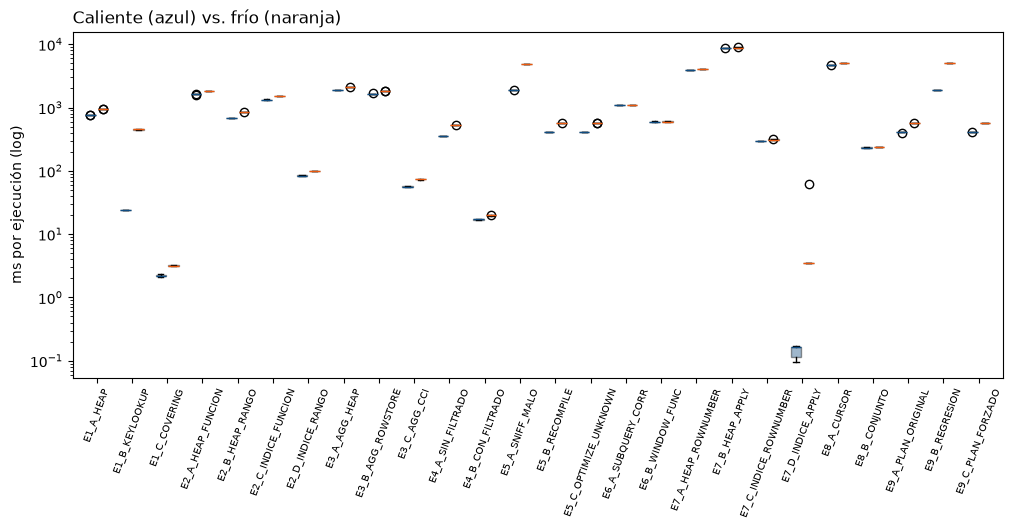

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
codigos = list(exp['codigo_experimento'])
for modo, color, d in (('CALIENTE', '#0f4c81', -0.18), ('FRIO', '#ea580c', 0.18)):
    datos = [med[(med['codigo_experimento'] == c) & (med['modo'] == modo)]['duracion_ms'] for c in codigos]
    ax.boxplot(datos, positions=[i + d for i in range(len(codigos))], widths=0.3,
               patch_artist=True, boxprops=dict(facecolor=color, alpha=0.4), medianprops=dict(color=color))
ax.set_yscale('log')
ax.set_xticks(range(len(codigos)), codigos, rotation=70, fontsize=7)
ax.set_ylabel('ms por ejecución (log)')
ax.set_title('Caliente (azul) vs. frío (naranja)', loc='left')
plt.show()

## 2. Aislar el efecto de cada cambio (E2 y E7)
En un diseño 2×2 se ve qué parte de la mejora viene del índice y qué parte de la reescritura.

In [5]:
for pref in ('E2_', 'E7_'):
    sub = exp[exp['codigo_experimento'].str.startswith(pref)][['variante', 'rol_comparacion', 'lecturas_logicas', 'duracion_ms_caliente', 'duracion_ms_frio']]
    display(sub)

,variante,rol_comparacion,lecturas_logicas,duracion_ms_caliente,duracion_ms_frio
3,Heap + YEAR()/MONTH()/DAY(),ANTES,78325,1609.217,1816.689
4,Solo reescritura: Heap + rango >= / <,SOLO_REESCRITURA,78325,687.020,856.202
5,Solo índice: agrupado por fecha + YEAR()/MONTH...,SOLO_INDICE,78470,1337.175,1524.912
6,Ambos: agrupado por fecha + rango >= / <,DESPUES,5874,84.269,99.805


,variante,rol_comparacion,lecturas_logicas,duracion_ms_caliente,duracion_ms_frio
17,Heap + ROW_NUMBER(),ANTES,78325,3887.729,4078.328
18,Solo reescritura: Heap + CROSS APPLY TOP (10),SOLO_REESCRITURA,783250,8726.202,8885.633
19,"Solo índice: (estación, fecha) + ROW_NUMBER()",SOLO_INDICE,1236,299.622,312.510
20,"Ambos: (estación, fecha) + CROSS APPLY TOP (10)",DESPUES,31,0.166,3.526


In [6]:
e2 = exp[exp['codigo_experimento'].str.startswith('E2_')].set_index('rol_comparacion')
base = e2.loc['ANTES', 'lecturas_logicas']
for rol in ('SOLO_REESCRITURA', 'SOLO_INDICE', 'DESPUES'):
    print(f"E2 {rol:<17}: {dec(e2.loc[rol, 'lecturas_logicas'] / base * 100, 1)} % de las páginas del heap")

E2 SOLO_REESCRITURA : 100,0 % de las páginas del heap
E2 SOLO_INDICE      : 100,2 % de las páginas del heap
E2 DESPUES          : 7,5 % de las páginas del heap


**Lectura:** en E2 ni la reescritura sola (el heap no está ordenado por fecha) ni el índice solo (la función sobre la columna impide buscar en él) reducen las páginas leídas; la reescritura sola sí ahorra CPU porque deja de evaluar tres funciones por fila. Las lecturas solo bajan con los dos cambios juntos. En E7 el índice por estación hace la mayor parte del trabajo; `CROSS APPLY` sin índice es peor que la consulta original porque recorre la tabla una vez por estación.

## 3. Punto de inflexión del Key Lookup

,etiqueta_ventana,filas_calificadas,pct_tabla,lecturas_heap_scan,lecturas_forzado_lookup,lecturas_nocov_natural,operador_nocov_natural,lecturas_covering_seek,lecturas_columnstore
0,1 día,950,0.014,78325,3678,558,Clustered Index Seek (rango de fechas),558,2470
1,7 días,10490,0.158,78325,34086,4948,Clustered Index Seek (rango de fechas),1013,2056
2,14 días,22985,0.345,78325,73914,10721,Clustered Index Seek (rango de fechas),1013,2056
3,30 días,48100,0.723,78325,153969,21219,Clustered Index Seek (rango de fechas),1013,3849
4,60 días,108179,1.626,78325,345471,47146,Clustered Index Seek (rango de fechas),1013,7150
5,91 días (trimestre),175748,2.641,78325,560847,17144,Intersección de 2 índices,1013,10166


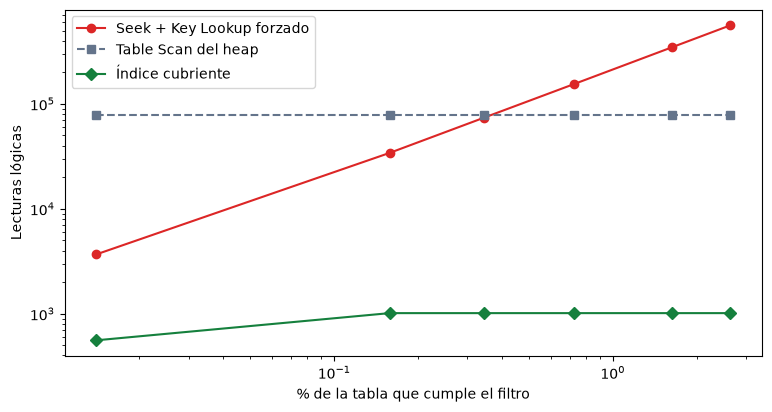

In [7]:
tp = leer('curva_tipping_point')
display(tp[['etiqueta_ventana', 'filas_calificadas', 'pct_tabla', 'lecturas_heap_scan', 'lecturas_forzado_lookup',
            'lecturas_nocov_natural', 'operador_nocov_natural', 'lecturas_covering_seek', 'lecturas_columnstore']])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tp['pct_tabla'], tp['lecturas_forzado_lookup'], 'o-', color='#dc2626', label='Seek + Key Lookup forzado')
ax.plot(tp['pct_tabla'], tp['lecturas_heap_scan'], 's--', color='#64748b', label='Table Scan del heap')
ax.plot(tp['pct_tabla'], tp['lecturas_covering_seek'], 'D-', color='#15803d', label='Índice cubriente')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('% de la tabla que cumple el filtro'); ax.set_ylabel('Lecturas lógicas')
ax.legend(); plt.show()

In [8]:
import numpy as np
# Punto de cruce aproximado (interpolación log-log entre las dos ventanas que lo rodean)
d = np.log(tp['lecturas_forzado_lookup']) - np.log(tp['lecturas_heap_scan'])
i = int(np.argmax(d.to_numpy() > 0))
x0, x1 = np.log(tp.loc[i - 1, 'pct_tabla']), np.log(tp.loc[i, 'pct_tabla'])
cruce = np.exp(x0 + (0 - d[i - 1]) * (x1 - x0) / (d[i] - d[i - 1]))
print(f'El Key Lookup forzado empieza a leer más páginas que el scan completo hacia el {dec(cruce, 2)} % de la tabla')

El Key Lookup forzado empieza a leer más páginas que el scan completo hacia el 0,37 % de la tabla


## 4. Parameter sniffing (E5) y plan forzado con Query Store (E9)

In [9]:
display(exp[exp['codigo_experimento'].str.match('E5_|E9_')][['codigo_experimento', 'variante', 'operador_principal',
        'filas_estimadas_acceso', 'filas_reales_acceso', 'lecturas_logicas', 'duracion_ms_caliente', 'duracion_ms_frio']])
leer('demo_plan_forzado')

,codigo_experimento,variante,operador_principal,filas_estimadas_acceso,filas_reales_acceso,lecturas_logicas,duracion_ms_caliente,duracion_ms_frio
12,E5_A_SNIFF_MALO,Plan compilado para @p = 80.000 y reutilizado ...,Index Seek + Key Lookup,871.38,853566,2722865,1922.701,4877.945
13,E5_B_RECOMPILE,OPTION (RECOMPILE): plan nuevo en cada ejecución,Clustered Index Scan,854050.00,0,78516,412.217,578.481
14,E5_C_OPTIMIZE_UNKNOWN,OPTION (OPTIMIZE FOR UNKNOWN): plan para un va...,Clustered Index Scan,1996200.00,853566,78470,406.317,569.232
23,E9_A_PLAN_ORIGINAL,Plan original compilado con @p = 1.200,Clustered Index Scan,854050.00,853566,78470,407.058,570.010
24,E9_B_REGRESION,Regresión: plan recompilado con @p = 80.000,Index Seek + Key Lookup,871.38,853566,2722865,1910.387,4981.958
25,E9_C_PLAN_FORZADO,sp_query_store_force_plan: plan original forzado,Clustered Index Scan,871.38,853566,78470,406.452,569.139


,paso,descripcion,query_id,plan_id,tiene_key_lookup,es_plan_forzado,fallos_forzado
0,1,Plan original (compilado con @p = 1.200),44,46,False,False,NaN
1,2,Plan de la regresión (compilado con @p = 80.000),44,47,True,False,NaN
2,3,Plan usado tras forzar (recompilado otra vez c...,44,46,False,True,0.0


**Lectura:** el plan compilado para un umbral de 80.000 s estima casi ninguna fila y elige *Index Seek + Key Lookup*; reutilizado con 1.200 s hace un lookup por cada fila. `RECOMPILE` y `OPTIMIZE FOR UNKNOWN` vuelven al escaneo. En E9 la misma regresión se corrige sin tocar el código: `sp_query_store_force_plan` fija el plan original y, aunque la consulta se recompile con el valor atípico, Query Store aplica el plan forzado.

## 5. Almacenamiento y tiempo de carga

In [10]:
display(leer('huella_almacenamiento'))
carga = leer('tiempos_carga')
carga[['estrategia', 'descripcion', 'corridas', 'mediana_ms_insercion', 'mediana_ms_indices', 'mediana_ms_total', 'min_ms_total', 'max_ms_total']]

,orden,objeto_sql,arquitectura,filas,datos_mb,indices_secund_mb,total_reservado_mb,paginas_datos_8kb,bytes_por_fila,ratio_compresion_vs_heap
0,1,lab.viaje_heap,Heap sin índices (línea base),6653987,611.60,0.00,611.64,78285,96.38,1.00
1,2,lab.viaje_rowstore_nocov,Rowstore B-Tree + índices no cubrientes,6653987,613.05,303.46,916.66,78471,96.61,1.00
2,3,lab.viaje_rowstore,Rowstore B-Tree + índice cubriente INCLUDE + f...,6653987,613.05,296.22,909.46,78470,96.61,1.00
3,4,lab.viaje_columnstore,Clustered Columnstore Index (CCI),6653987,188.88,0.00,189.01,24176,29.76,3.24


,estrategia,descripcion,corridas,mediana_ms_insercion,mediana_ms_indices,mediana_ms_total,min_ms_total,max_ms_total
0,HEAP,Heap sin índices,3,4478.0,0.0,4478.0,4358,5065
1,INDICES_DESPUES,"Agrupado + INSERT, luego CREATE de 2 índices s...",3,16547.0,23837.0,40322.0,39496,40689
2,INDICES_ANTES,Agrupado + 2 índices secundarios ya creados an...,3,63957.0,0.0,63957.0,62760,65672
